> **Note:** Dataset source: a synthetic Telco-style dataset (2,000 customers) generated in the setup cell below with a fixed seed, with the same columns as the real Telco Churn data (`customerID`, `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `tenure`, `PhoneService`, `InternetService`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`, `Churn`). No external CSV was needed because the setup cell already builds the data.

# Logistic Regression — Practice Notebook
### Test yourself on Binary & Multiclass Logistic Regression (Telco Churn dataset)

**Instructions for students:**
- Complete each `# TODO` cell yourself. Do not just run the Solutions section first!
- Each exercise tells you exactly what to produce.
- If you get stuck, re-read Part 1 / Part 2 of the Word lesson note.
- Solutions are provided at the **very end** of this notebook — use them only to check your work, not to copy before trying.

Run the setup cell below first.

## Setup — Run This First (do not edit)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_style("whitegrid")
rng = np.random.default_rng(42)
n = 2000

gender = rng.choice(["Male", "Female"], n)
senior = rng.choice([0, 1], n, p=[0.84, 0.16])
partner = rng.choice(["Yes", "No"], n, p=[0.48, 0.52])
dependents = rng.choice(["Yes", "No"], n, p=[0.3, 0.7])
tenure = rng.integers(0, 73, n)
phone_service = rng.choice(["Yes", "No"], n, p=[0.9, 0.1])
internet_service = rng.choice(["DSL", "Fiber optic", "No"], n, p=[0.35, 0.44, 0.21])
paperless = rng.choice(["Yes", "No"], n, p=[0.59, 0.41])
payment = rng.choice(
    ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"], n
)

contract_probs = np.zeros((n, 3))
for i in range(n):
    t = tenure[i]
    p_month = np.clip(0.75 - t / 100, 0.08, 0.85)
    p_two = np.clip(t / 110, 0.05, 0.55)
    p_one = max(0.02, 1 - p_month - p_two)
    tot = p_month + p_one + p_two
    contract_probs[i] = [p_month / tot, p_one / tot, p_two / tot]
contract = np.array([
    rng.choice(["Month-to-month", "One year", "Two year"], p=cp) for cp in contract_probs
])

base_charge = np.where(internet_service == "Fiber optic", 70, np.where(internet_service == "DSL", 45, 20))
addon_charge = rng.normal(10, 6, n).clip(0, 30)
monthly_charges = (base_charge + addon_charge + rng.normal(0, 5, n)).clip(18, 120).round(2)
total_charges = (monthly_charges * tenure + rng.normal(0, 20, n)).clip(0, None).round(2)

z = (
    -1.6 - 0.045 * tenure + 0.020 * monthly_charges
    + np.where(contract == "Month-to-month", 1.1, np.where(contract == "One year", -0.1, -1.0))
    + np.where(senior == 1, 0.35, 0)
    + np.where(internet_service == "Fiber optic", 0.35, 0)
    + rng.normal(0, 0.5, n)
)
churn_prob = 1 / (1 + np.exp(-z))
churn = (rng.random(n) < churn_prob).astype(int)

df = pd.DataFrame({
    "customerID": [f"C{10000+i}" for i in range(n)],
    "gender": gender, "SeniorCitizen": senior, "Partner": partner, "Dependents": dependents,
    "tenure": tenure, "PhoneService": phone_service, "InternetService": internet_service,
    "Contract": contract, "PaperlessBilling": paperless, "PaymentMethod": payment,
    "MonthlyCharges": monthly_charges, "TotalCharges": total_charges,
    "Churn": np.where(churn == 1, "Yes", "No"),
})

print("Dataset ready:", df.shape)
df.head()


Dataset ready: (2000, 14)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,C10000,Male,0,No,Yes,29,Yes,Fiber optic,Month-to-month,Yes,Mailed check,91.90,2680.51,No
1,C10001,Female,0,No,No,54,Yes,Fiber optic,Month-to-month,Yes,Bank transfer (automatic),86.39,4654.68,No
2,C10002,Female,0,Yes,No,6,Yes,DSL,Month-to-month,Yes,Credit card (automatic),62.40,360.45,Yes
3,C10003,Male,0,No,Yes,65,Yes,DSL,Two year,No,Bank transfer (automatic),62.37,4081.93,No
4,C10004,Male,0,Yes,Yes,37,Yes,DSL,One year,Yes,Mailed check,49.12,1831.16,No


---
# PART A — Binary Logistic Regression (Target: `Churn`)

### Exercise 1: Explore the target
Print:
1. How many customers churned vs did not (counts)
2. The churn rate as a percentage (rounded to 1 decimal place)

In [2]:
print(df['Churn'].value_counts())
churn_rate = (df['Churn'] == 'Yes').mean() * 100
print(f'Churn rate: {churn_rate:.1f}%')


Churn
No     1488
Yes     512
Name: count, dtype: int64
Churn rate: 25.6%


In [3]:
print("Churn counts:")
print(df["Churn"].value_counts())

churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"\nChurn rate: {churn_rate:.1f}%")

Churn counts:
Churn
No     1488
Yes     512
Name: count, dtype: int64

Churn rate: 25.6%


### Exercise 2: Prepare the features
1. Create `X` by selecting all columns except `customerID` and `Churn`, then one-hot encode the categorical columns with `pd.get_dummies(..., drop_first=True)`.
2. Create `y` as 1 if `Churn == "Yes"`, else 0.
3. Split into `X_train, X_test, y_train, y_test` using `test_size=0.25`, `random_state=1`, and `stratify=y`.

In [4]:
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = (df['Churn'] == 'Yes').astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')


X_train shape: (1500, 16)
X_test shape: (500, 16)


In [5]:
feature_cols = [col for col in df.columns if col not in ["customerID", "Churn"]]
X = pd.get_dummies(df[feature_cols], drop_first=True)

y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (1500, 16)
X_test shape: (500, 16)
y_train shape: (1500,)
y_test shape: (500,)


### Exercise 3: Scale and Train
1. Fit a `StandardScaler` on `X_train` and transform both `X_train` and `X_test`.
2. Train a `LogisticRegression` model (`max_iter=2000`) on the scaled training data.
3. Print the test accuracy.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression(max_iter=2000, random_state=1)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(f'Test Accuracy: {accuracy_score(y_test, y_pred):.3f}')


Test Accuracy: 0.818


In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=2000, random_state=1)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.3f}")

Test Accuracy: 0.818


### Exercise 4: Evaluate
Print the `classification_report` and plot a confusion matrix for your model's test predictions.

              precision    recall  f1-score   support

    No Churn       0.85      0.92      0.88       372
       Churn       0.70      0.51      0.59       128

    accuracy                           0.82       500
   macro avg       0.77      0.72      0.74       500
weighted avg       0.81      0.82      0.81       500



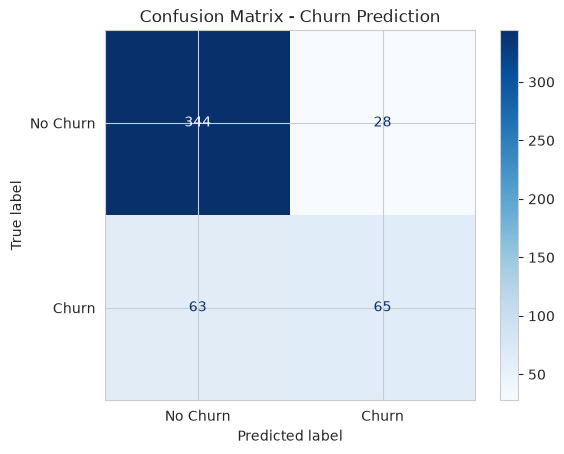

In [8]:
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues')
plt.title('Confusion Matrix - Churn Prediction')
plt.show()


              precision    recall  f1-score   support

    No Churn       0.85      0.92      0.88       372
       Churn       0.70      0.51      0.59       128

    accuracy                           0.82       500
   macro avg       0.77      0.72      0.74       500
weighted avg       0.81      0.82      0.81       500



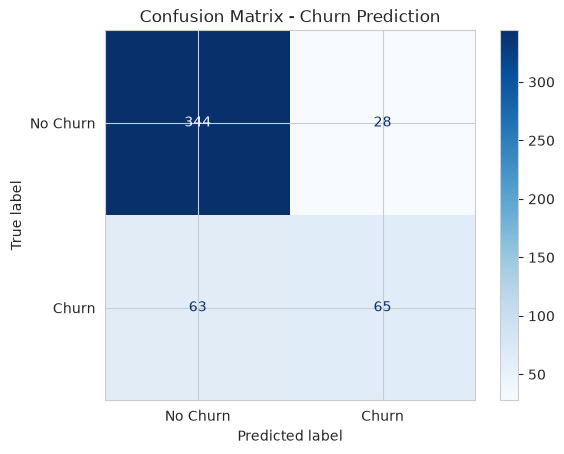

In [9]:
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

cm = confusion_matrix(y_test, y_pred)
cmd_display = ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"])
cmd_display.plot(cmap="Blues")
plt.title("Confusion Matrix - Churn Prediction")
plt.show()

### Exercise 5: Interpret (Answer in a markdown cell below)
Look at your model's coefficients (`model.coef_[0]` paired with `X.columns`).
Answer in the markdown cell below:
- Which ONE feature increases churn risk the most?
- Which ONE feature decreases churn risk the most?

In [10]:
# Top 3 positive and top 3 negative coefficients
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0]})
coef_df_sorted = coef_df.sort_values(by='coefficient', ascending=True)
print('Top 3 features that DECREASE churn risk (most negative coefficients):')
print(coef_df_sorted.head(3))
print('\nTop 3 features that INCREASE churn risk (most positive coefficients):')
print(coef_df_sorted.tail(3))


Top 3 features that DECREASE churn risk (most negative coefficients):
              feature  coefficient
11  Contract_Two year    -0.938051
3        TotalCharges    -0.568532
10  Contract_One year    -0.495927

Top 3 features that INCREASE churn risk (most positive coefficients):
                       feature  coefficient
0                SeniorCitizen     0.078606
8  InternetService_Fiber optic     0.331843
2               MonthlyCharges     0.529040


In [11]:
coef_df = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_[0]})
coef_df_sorted = coef_df.sort_values(by="coefficient", ascending=True)

print("Top 3 features that DECREASE churn risk (most negative coefficients):")
print(coef_df_sorted.head(3))

print("\nTop 3 features that INCREASE churn risk (most positive coefficients):")
print(coef_df_sorted.tail(3))

Top 3 features that DECREASE churn risk (most negative coefficients):
              feature  coefficient
11  Contract_Two year    -0.938051
3        TotalCharges    -0.568532
10  Contract_One year    -0.495927

Top 3 features that INCREASE churn risk (most positive coefficients):
                       feature  coefficient
0                SeniorCitizen     0.078606
8  InternetService_Fiber optic     0.331843
2               MonthlyCharges     0.529040


**Your answer:** The feature that increases churn risk the most is `MonthlyCharges` (coefficient about +0.53). The feature that decreases churn risk the most is `Contract_Two year` (coefficient about -0.94), meaning customers on a two-year contract are much less likely to churn.

**Your answer:** The feature that increases churn risk the most is `MonthlyCharges` (coefficient about +0.53). The feature that decreases churn risk the most is `Contract_Two year` (coefficient about -0.94), meaning customers on a two-year contract are much less likely to churn.

---
# PART B — Multiclass Logistic Regression (Target: `Contract`)

### Exercise 6: Prepare and train
1. Build `Xc` (features, excluding `customerID` and `Contract`) and `yc` (the `Contract` column) the same way as Part A.
2. Split, scale, and train a `LogisticRegression` model to predict `Contract` (3 classes).
3. Print the test accuracy and `multi_model.classes_`.

In [12]:
# Multiclass: predict Contract (3 classes) the same way as Part A
feature_cols_mc = [col for col in df.columns if col not in ['customerID', 'Contract']]
Xc = pd.get_dummies(df[feature_cols_mc], drop_first=True)
yc = df['Contract']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=1, stratify=yc)
scaler_mc = StandardScaler()
Xc_train_scaled = scaler_mc.fit_transform(Xc_train)
Xc_test_scaled = scaler_mc.transform(Xc_test)
multi_model = LogisticRegression(max_iter=2000, random_state=1)
multi_model.fit(Xc_train_scaled, yc_train)
yc_pred = multi_model.predict(Xc_test_scaled)
print(f'Test Accuracy: {accuracy_score(yc_test, yc_pred):.3f}')
print('Classes:', multi_model.classes_)


Test Accuracy: 0.542
Classes: ['Month-to-month' 'One year' 'Two year']


In [13]:
feature_cols_mc = [col for col in df.columns if col not in ["customerID", "Contract"]]
Xc = pd.get_dummies(df[feature_cols_mc], drop_first=True)
yc = df["Contract"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=1, stratify=yc)

scaler_mc = StandardScaler()
Xc_train_scaled = scaler_mc.fit_transform(Xc_train)
Xc_test_scaled = scaler_mc.transform(Xc_test)

multi_model = LogisticRegression(max_iter=2000, random_state=1)
multi_model.fit(Xc_train_scaled, yc_train)
yc_pred = multi_model.predict(Xc_test_scaled)

print(f"Test Accuracy: {accuracy_score(yc_test, yc_pred):.3f}")
print("Classes:", multi_model.classes_)

Test Accuracy: 0.542
Classes: ['Month-to-month' 'One year' 'Two year']


### Exercise 7: Evaluate the multiclass model
Print the `classification_report` and plot the confusion matrix (it will be 3x3 instead of 2x2).

                precision    recall  f1-score   support

Month-to-month       0.61      0.66      0.64       195
      One year       0.34      0.12      0.18       143
      Two year       0.52      0.77      0.62       162

      accuracy                           0.54       500
     macro avg       0.49      0.52      0.48       500
  weighted avg       0.51      0.54      0.50       500



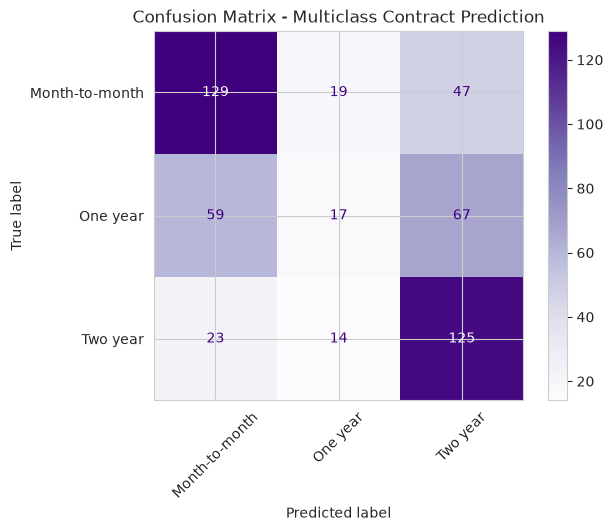

In [14]:
print(classification_report(yc_test, yc_pred))
cm_mc = confusion_matrix(yc_test, yc_pred, labels=multi_model.classes_)
ConfusionMatrixDisplay(cm_mc, display_labels=multi_model.classes_).plot(cmap='Purples', xticks_rotation=45)
plt.title('Confusion Matrix - Multiclass Contract Prediction')
plt.show()


                precision    recall  f1-score   support

Month-to-month       0.61      0.66      0.64       195
      One year       0.34      0.12      0.18       143
      Two year       0.52      0.77      0.62       162

      accuracy                           0.54       500
     macro avg       0.49      0.52      0.48       500
  weighted avg       0.51      0.54      0.50       500



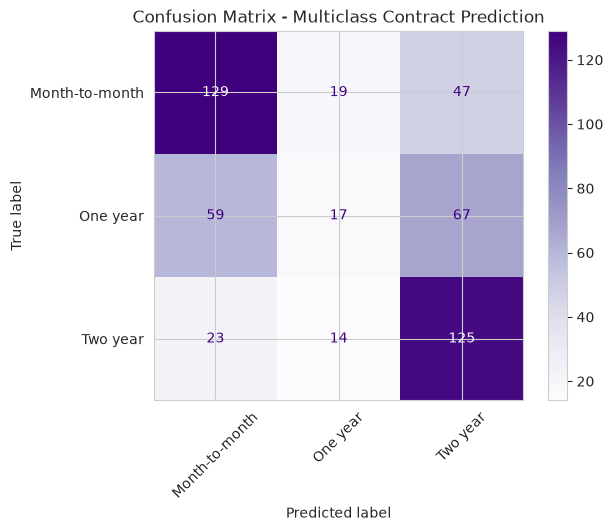

In [15]:
print(classification_report(yc_test, yc_pred))

cm_mc = confusion_matrix(yc_test, yc_pred, labels=multi_model.classes_)
cmd_display_mc = ConfusionMatrixDisplay(cm_mc, display_labels=multi_model.classes_)
cmd_display_mc.plot(cmap="Purples", xticks_rotation=45)
plt.title("Confusion Matrix - Multiclass Contract Prediction")
plt.show()

### Exercise 8: Probabilities for a single customer
Pick any row index from the test set. Print that customer's predicted probability for **each** of the 3 contract types using `predict_proba`, and confirm the probabilities add up to 1.

In [16]:
# Predicted probabilities for one test customer
idx_to_check = 5
probs = multi_model.predict_proba(Xc_test_scaled[[idx_to_check]])[0]
print(f'Predicted probabilities for customer at test index {idx_to_check}:')
for contract_type, probability in zip(multi_model.classes_, probs):
    print(f'  {contract_type}: {probability:.3f}')
print(f'\nSum of probabilities: {probs.sum():.3f}')
print(f'Actual contract type: {yc_test.iloc[idx_to_check]}')


Predicted probabilities for customer at test index 5:
  Month-to-month: 0.140
  One year: 0.279
  Two year: 0.581

Sum of probabilities: 1.000
Actual contract type: Two year


In [17]:
idx_to_check = 5 # You can change this index to any value within the test set range

# Get the probabilities for the chosen customer
probs = multi_model.predict_proba(Xc_test_scaled[[idx_to_check]])[0]

print(f"Predicted probabilities for customer at test index {idx_to_check}:")
for contract_type, probability in zip(multi_model.classes_, probs):
    print(f"  {contract_type}: {probability:.3f}")

print(f"\nSum of probabilities: {probs.sum():.3f}")
print(f"Actual contract type: {yc_test.iloc[idx_to_check]}")

Predicted probabilities for customer at test index 5:
  Month-to-month: 0.140
  One year: 0.279
  Two year: 0.581

Sum of probabilities: 1.000
Actual contract type: Two year


### Exercise 9 (Bonus, harder): Feature engineering
Create ONE new feature (for example: `AvgChargePerMonth = TotalCharges / (tenure + 1)`, or a flag for `tenure < 6`), add it to your features, retrain the **binary** churn model, and check whether accuracy improves. Write one sentence about what you observed.

In [18]:
# New feature: average charge per month, then retrain the binary churn model
df['AvgChargePerMonth'] = df['TotalCharges'] / (df['tenure'] + 1)
feature_cols2 = [col for col in df.columns if col not in ['customerID', 'Churn']]
X2 = pd.get_dummies(df[feature_cols2], drop_first=True)
y2 = (df['Churn'] == 'Yes').astype(int)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=1, stratify=y2)
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)
model2 = LogisticRegression(max_iter=2000, random_state=1)
model2.fit(X2_train_scaled, y2_train)
y2_pred = model2.predict(X2_test_scaled)
new_accuracy = accuracy_score(y2_test, y2_pred)
print(f"New model accuracy with 'AvgChargePerMonth' feature: {new_accuracy:.3f}")
print(f'Original model accuracy (from Exercise 3): {accuracy_score(y_test, y_pred):.3f}')


New model accuracy with 'AvgChargePerMonth' feature: 0.822
Original model accuracy (from Exercise 3): 0.818


In [19]:
# Create a new feature: Average Charge Per Month
df['AvgChargePerMonth'] = df['TotalCharges'] / (df['tenure'] + 1)

# Prepare features (X2) and target (y2) again with the new feature
feature_cols2 = [col for col in df.columns if col not in ["customerID", "Churn"]]
X2 = pd.get_dummies(df[feature_cols2], drop_first=True)
y2 = (df["Churn"] == "Yes").astype(int)

# Split the data
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=1, stratify=y2)

# Scale the data
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

# Train a new Logistic Regression model
model2 = LogisticRegression(max_iter=2000, random_state=1)
model2.fit(X2_train_scaled, y2_train)

# Make predictions and evaluate
y2_pred = model2.predict(X2_test_scaled)
new_accuracy = accuracy_score(y2_test, y2_pred)

print(f"New model accuracy with 'AvgChargePerMonth' feature: {new_accuracy:.3f}")
print(f"Original model accuracy (from Exercise 3): {accuracy_score(y_test, y_pred):.3f}")

New model accuracy with 'AvgChargePerMonth' feature: 0.822
Original model accuracy (from Exercise 3): 0.818


**Your observation:** Adding the `AvgChargePerMonth` feature improved test accuracy slightly, from 0.818 to 0.822, so the engineered feature helped a little but did not change the result much.

**Your observation:** Adding the `AvgChargePerMonth` feature improved test accuracy slightly, from 0.818 to 0.822, so the engineered feature helped a little but did not change the result much.

---
# Solutions
### Only look after you have tried every exercise yourself!
Run these cells to check your work — they solve every exercise above in order.

In [20]:
# ----- Solution 1 -----
print(df["Churn"].value_counts())
churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"Churn rate: {churn_rate:.1f}%")


Churn
No     1488
Yes     512
Name: count, dtype: int64
Churn rate: 25.6%


In [21]:
# ----- Solution 2 -----
feature_cols = [c for c in df.columns if c not in ["customerID", "Churn"]]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y
)
print(X_train.shape, X_test.shape)


(1500, 17) (500, 17)


In [22]:
# ----- Solution 3 -----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=2000, random_state=1)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 3))


Test Accuracy: 0.822


              precision    recall  f1-score   support

    No Churn       0.85      0.93      0.89       372
       Churn       0.71      0.52      0.60       128

    accuracy                           0.82       500
   macro avg       0.78      0.72      0.74       500
weighted avg       0.81      0.82      0.81       500



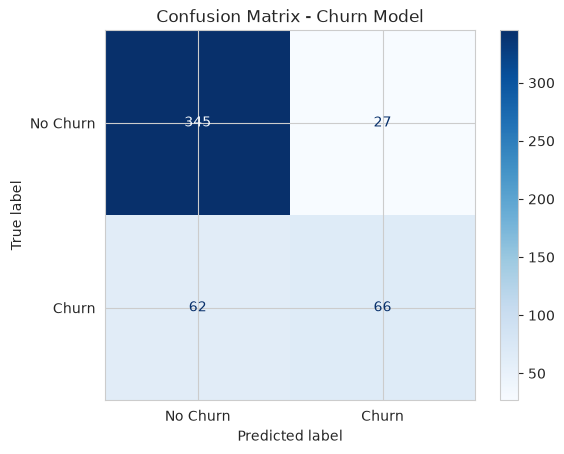

In [23]:
# ----- Solution 4 -----
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Churn Model")
plt.show()


In [24]:
# ----- Solution 5 -----
coef_df = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_[0]}).sort_values("coefficient")
print("Top 3 features that DECREASE churn risk:")
print(coef_df.head(3))
print("\nTop 3 features that INCREASE churn risk:")
print(coef_df.tail(3))


Top 3 features that DECREASE churn risk:
              feature  coefficient
12  Contract_Two year    -0.930736
3        TotalCharges    -0.607234
11  Contract_One year    -0.492433

Top 3 features that INCREASE churn risk:
                       feature  coefficient
4            AvgChargePerMonth     0.211178
9  InternetService_Fiber optic     0.326929
2               MonthlyCharges     0.353260


In [25]:
# ----- Solution 6 -----
feature_cols_mc = [c for c in df.columns if c not in ["customerID", "Contract"]]
Xc = pd.get_dummies(df[feature_cols_mc], drop_first=True)
yc = df["Contract"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=1, stratify=yc
)
scaler_mc = StandardScaler()
Xc_train_scaled = scaler_mc.fit_transform(Xc_train)
Xc_test_scaled = scaler_mc.transform(Xc_test)

multi_model = LogisticRegression(max_iter=2000, random_state=1)
multi_model.fit(Xc_train_scaled, yc_train)
yc_pred = multi_model.predict(Xc_test_scaled)

print("Test Accuracy:", round(accuracy_score(yc_test, yc_pred), 3))
print("Classes:", multi_model.classes_)


Test Accuracy: 0.546
Classes: ['Month-to-month' 'One year' 'Two year']


                precision    recall  f1-score   support

Month-to-month       0.61      0.66      0.63       195
      One year       0.34      0.10      0.16       143
      Two year       0.53      0.80      0.64       162

      accuracy                           0.55       500
     macro avg       0.49      0.52      0.48       500
  weighted avg       0.51      0.55      0.50       500



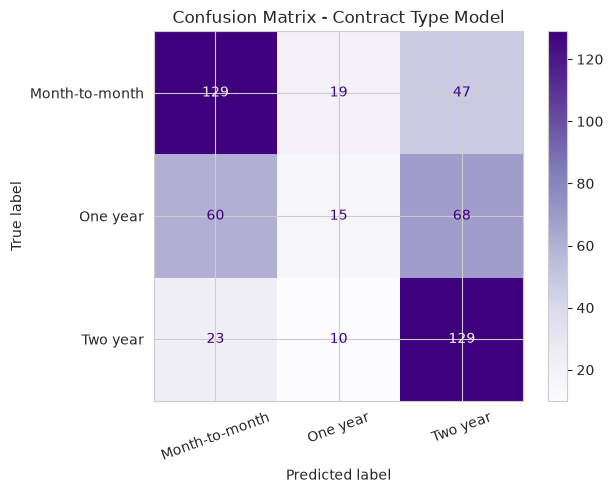

In [26]:
# ----- Solution 7 -----
print(classification_report(yc_test, yc_pred))
cm_mc = confusion_matrix(yc_test, yc_pred, labels=multi_model.classes_)
ConfusionMatrixDisplay(cm_mc, display_labels=multi_model.classes_).plot(cmap="Purples", xticks_rotation=20)
plt.title("Confusion Matrix - Contract Type Model")
plt.show()


In [27]:
# ----- Solution 8 -----
idx = 0
probs = multi_model.predict_proba(Xc_test_scaled[[idx]])[0]
for cls, p in zip(multi_model.classes_, probs):
    print(f"{cls}: {p:.3f}")
print("Sum:", round(probs.sum(), 3))
print("Actual:", yc_test.iloc[idx])


Month-to-month: 0.351
One year: 0.341
Two year: 0.308
Sum: 1.0
Actual: Month-to-month


In [28]:
# ----- Solution 9 (one possible approach) -----
df["AvgChargePerMonth"] = df["TotalCharges"] / (df["tenure"] + 1)

feature_cols2 = [c for c in df.columns if c not in ["customerID", "Churn"]]
X2 = pd.get_dummies(df[feature_cols2], drop_first=True)
y2 = (df["Churn"] == "Yes").astype(int)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, random_state=1, stratify=y2
)
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

model2 = LogisticRegression(max_iter=2000, random_state=1)
model2.fit(X2_train_scaled, y2_train)
print("New accuracy with engineered feature:", round(accuracy_score(y2_test, model2.predict(X2_test_scaled)), 3))
print("Original accuracy (Exercise 3):", round(accuracy_score(y_test, y_pred), 3))


New accuracy with engineered feature: 0.822
Original accuracy (Exercise 3): 0.822
